In [1]:
!git clone https://github.com/AiArt-Gao/HMEG.git
%cd /content/HMEG
!pip install -q pillow matplotlib scipy tqdm networkx opencv-python tensorboardX gdown pandas numpy


Cloning into 'HMEG'...
remote: Enumerating objects: 117, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 117 (delta 17), reused 95 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (117/117), 1.22 MiB | 4.04 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/HMEG
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 3.4 MB/s eta 0:00:00


In [2]:
%cd /content/HMEG

import shutil, tarfile, zipfile
from pathlib import Path

!rm -rf /content/HMEG_assets
!mkdir -p /content/HMEG_assets
!gdown --folder "https://drive.google.com/drive/folders/1lTsny6ZpaCpw8N7xfScbSqiOGpjt1JGY" -O /content/HMEG_assets --remaining-ok

root = Path('/content/HMEG_assets')
Path('/content/HMEG/weight').mkdir(parents=True, exist_ok=True)
Path('/content/datasets').mkdir(parents=True, exist_ok=True)

shutil.copy(root / 'layout_conv_sum2_new_with_model.pt', '/content/HMEG/weight/layout_conv_sum2_new_with_model.pt')
shutil.copy(root / 'box_net_40000.pkl', '/content/HMEG/weight/box_net_40000.pkl')
shutil.copy(root / 'box_net_40000.pkl', '/content/HMEG/weight/box_net_nosub_40000.pkl')

if Path('/content/datasets/crohme2019').exists():
    shutil.rmtree('/content/datasets/crohme2019')
with tarfile.open(root / 'crohme2019.tar.bz2', 'r:bz2') as tar:
    tar.extractall('/content/datasets')

if Path('/content/HMEG/Train_symlg').exists():
    shutil.rmtree('/content/HMEG/Train_symlg')
with zipfile.ZipFile(root / 'Train_symlg.zip', 'r') as z:
    z.extractall('/content/HMEG')

!ls -lh /content/HMEG/weight
!find /content/HMEG/Train_symlg -name "*.lg" | head


/content/HMEG
Retrieving folder contents
Processing file 1iI6kqMFBJuHY2YvLRrkdV47VtrRBsDRo box_net_40000.pkl
Processing file 17t-ZZ40Kg_uyWku7hPqo6yfaXXRI1fE6 crohme2019.tar.bz2
Processing file 1tG_3tPn9TOujpgUHTSj6jGF7gqXcPk3U layout_conv_sum2_new_with_model.pt
Processing file 17oA1lumCF8dWL72xKl7b3aK2e_Fvie4Z Train_symlg.zip
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1iI6kqMFBJuHY2YvLRrkdV47VtrRBsDRo
From (redirected): https://drive.google.com/uc?id=1iI6kqMFBJuHY2YvLRrkdV47VtrRBsDRo&confirm=t&uuid=f09ab6d9-943f-4493-ad6c-4c5bcf0e1740
To: /content/HMEG_assets/box_net_40000.pkl
100% 69.7M/69.7M [00:00<00:00, 85.0MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=17t-ZZ40Kg_uyWku7hPqo6yfaXXRI1fE6
From (redirected): https://drive.google.com/uc?id=17t-ZZ40Kg_uyWku7hPqo6yfaXXRI1fE6&confirm=t&uuid=e52a09f2-88ca-4a92-88b7-255c936d951a
To: /content/HME

/tmp/ipykernel_1494/1868179778.py:21: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content/datasets')


total 1.6G
-rw-r--r-- 1 root root  67M May  6 12:24 box_net_40000.pkl
-rw-r--r-- 1 root root  67M May  6 12:24 box_net_nosub_40000.pkl
-rw-r--r-- 1 root root 1.5G May  6 12:24 layout_conv_sum2_new_with_model.pt
/content/HMEG/Train_symlg/200923-1556-245.lg
/content/HMEG/Train_symlg/2009212-1031-37.lg
/content/HMEG/Train_symlg/200923-1254-104.lg
/content/HMEG/Train_symlg/200925-1126-156.lg
/content/HMEG/Train_symlg/126_jorge.lg
/content/HMEG/Train_symlg/MfrDB0101.lg
/content/HMEG/Train_symlg/MfrDB3476.lg
/content/HMEG/Train_symlg/200922-949-115.lg
/content/HMEG/Train_symlg/200925-1126-1.lg
/content/HMEG/Train_symlg/MfrDB0347.lg


In [3]:
%cd /content/HMEG

from pathlib import Path
from PIL import Image, ImageOps, ImageEnhance, ImageDraw
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import shutil

_TRUE_TORCH_LOAD = torch.load

def safe_torch_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _TRUE_TORCH_LOAD(*args, **kwargs)

torch.load = safe_torch_load

import data.process as process

def fixed_convert(self, lg_path):
    graph = self.lg2graph(lg_path)
    edge_types = self._encode_edge_type(graph)
    node_types = np.asarray(graph['node_types'], dtype=np.int64)
    objs = torch.tensor(node_types, dtype=torch.long)
    n = objs.shape[0]
    triples = []
    for row in range(n):
        for col in range(n):
            triples.append([row, int(edge_types[row, col]), col])
    return objs, torch.LongTensor(triples)

process.CROHME2Graph.convert = fixed_convert

from predictor import Predictor
from data import imagenet_deprocess_batch

p = Predictor(
    args=None,
    gen_checkpoint_path='weight/layout_conv_sum2_new_with_model.pt',
    box_checkpoint_path='weight/box_net_40000.pkl'
)

lg_files = sorted(Path('/content/HMEG/Train_symlg').rglob('*.lg'))
print('LG files:', len(lg_files))


/content/HMEG
LG files: 8836


In [4]:
def count_lg_objects(lg_path):
    objs, rels = 0, 0
    with open(lg_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            s = line.strip()
            if s.startswith('O,'):
                objs += 1
            elif s.startswith('R,') or s.startswith('EO,'):
                rels += 1
    return objs, rels


def clean_soft(img_arr):
    img = Image.fromarray(img_arr).convert('L')
    arr = np.array(img)
    if arr.mean() < 127:
        img = ImageOps.invert(img)
    inv = ImageOps.invert(img)
    bbox = inv.getbbox()
    if not bbox:
        return None
    img = img.crop(bbox)
    if img.width < 35 or img.height < 20:
        return None
    aspect = img.width / max(img.height, 1)
    if aspect > 8 or aspect < 0.6:
        return None
    img = ImageEnhance.Contrast(img).enhance(1.25)
    img = img.resize((img.width * 3, img.height * 3), Image.Resampling.LANCZOS)
    bg = Image.new('L', (img.width + 70, img.height + 70), 255)
    bg.paste(img, (35, 35))
    return bg


def readability_score(img, obj_count, rel_count):
    arr = np.array(img.convert('L'))
    ink = arr < 220
    ink_ratio = float(ink.mean())
    if ink_ratio < 0.003 or ink_ratio > 0.22:
        return -1.0
    aspect = img.width / max(img.height, 1)
    medium_complexity = max(0.0, 1.0 - abs(obj_count - 12) / 12)
    aspect_score = max(0.0, 1.0 - abs(aspect - 3.0) / 4.0)
    return 2.0 * medium_complexity + 1.5 * aspect_score + ink_ratio


def predict_image(lg):
    with torch.no_grad():
        res = p.predict([str(lg)])
        imgs = imagenet_deprocess_batch(res[2].detach().cpu())
    im = imgs[0].squeeze().permute(1, 2, 0).numpy()
    if im.dtype != np.uint8:
        im = np.clip(im, 0, 255).astype(np.uint8)
    return im


/content/HMEG/model/crn.py:96: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:101: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:105: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')


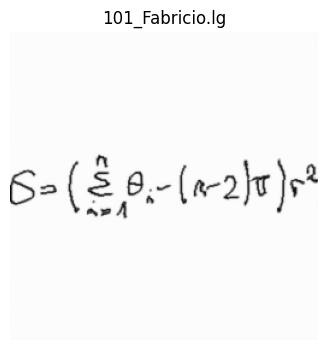

In [5]:
sample_lg = lg_files[0]
im = predict_image(sample_lg)
Image.fromarray(im).save('/content/hmeg_smoke.png')
plt.figure(figsize=(8, 4))
plt.imshow(im, cmap='gray')
plt.axis('off')
plt.title(sample_lg.name)
plt.show()


In [6]:
out_root = Path('/content/hmeg_project_outputs')
candidate_dir = out_root / 'hmeg_readable_candidates'
selected_dir = out_root / 'hmeg_readable_selected'
for d in [candidate_dir, selected_dir]:
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True, exist_ok=True)

candidates = []
for lg in lg_files:
    obj_count, rel_count = count_lg_objects(lg)
    if 6 <= obj_count <= 18 and 4 <= rel_count <= 20:
        bonus = 0.2 if 'formulaire' in lg.name.lower() else 0.0
        candidates.append((lg, obj_count, rel_count, bonus))

random.seed(7)
random.shuffle(candidates)
records = []

for lg, obj_count, rel_count, bonus in candidates[:1500]:
    try:
        im = predict_image(lg)
        clean = clean_soft(im)
        if clean is None:
            continue
        score = readability_score(clean, obj_count, rel_count) + bonus
        if score <= 0:
            continue
        path = candidate_dir / f'{lg.stem}_obj{obj_count}_rel{rel_count}.png'
        clean.save(path)
        records.append((score, path, obj_count, rel_count))
    except Exception:
        pass

records = sorted(records, key=lambda x: x[0], reverse=True)
for i, (score, path, obj_count, rel_count) in enumerate(records[:60]):
    out_name = f'{i:02d}_score{score:.2f}_{path.name}'
    Image.open(path).save(selected_dir / out_name)

print('usable:', len(records))
print('selected:', len(list(selected_dir.glob('*.png'))))


Streaming output truncated to the last 5000 lines.
/content/HMEG/model/crn.py:105: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:96: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:101: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:105: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/crn.py:96: UserWarning: `nn.functional.upsample` is deprecated. Use `nn.functional.interpolate` instead.
  feats = F.upsample(feats, scale_factor=2, mode='nearest')
/content/HMEG/model/c

usable: 1360
selected: 60


In [7]:
best_prefixes = {'06','07','09','11','17','20','21','23','26','28','29','34','42','48'}
extra_prefixes = {'01','04','13','16','18','25','38','40','44','45','47'}
showable_prefixes = best_prefixes | extra_prefixes

final_root = out_root / 'final'
best_dir = final_root / 'hmeg_final_best'
showable_dir = final_root / 'hmeg_final_showable'
reject_dir = final_root / 'hmeg_not_showable'
for d in [best_dir, showable_dir, reject_dir]:
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True, exist_ok=True)

for f in sorted(selected_dir.glob('*.png')):
    prefix = f.name.split('_', 1)[0]
    if prefix in showable_prefixes:
        shutil.copy2(f, showable_dir / f.name)
        if prefix in best_prefixes:
            shutil.copy2(f, best_dir / f.name)
    else:
        shutil.copy2(f, reject_dir / f.name)

print('best:', len(list(best_dir.glob('*.png'))))
print('showable:', len(list(showable_dir.glob('*.png'))))
print('rejected:', len(list(reject_dir.glob('*.png'))))


best: 14
showable: 25
rejected: 35


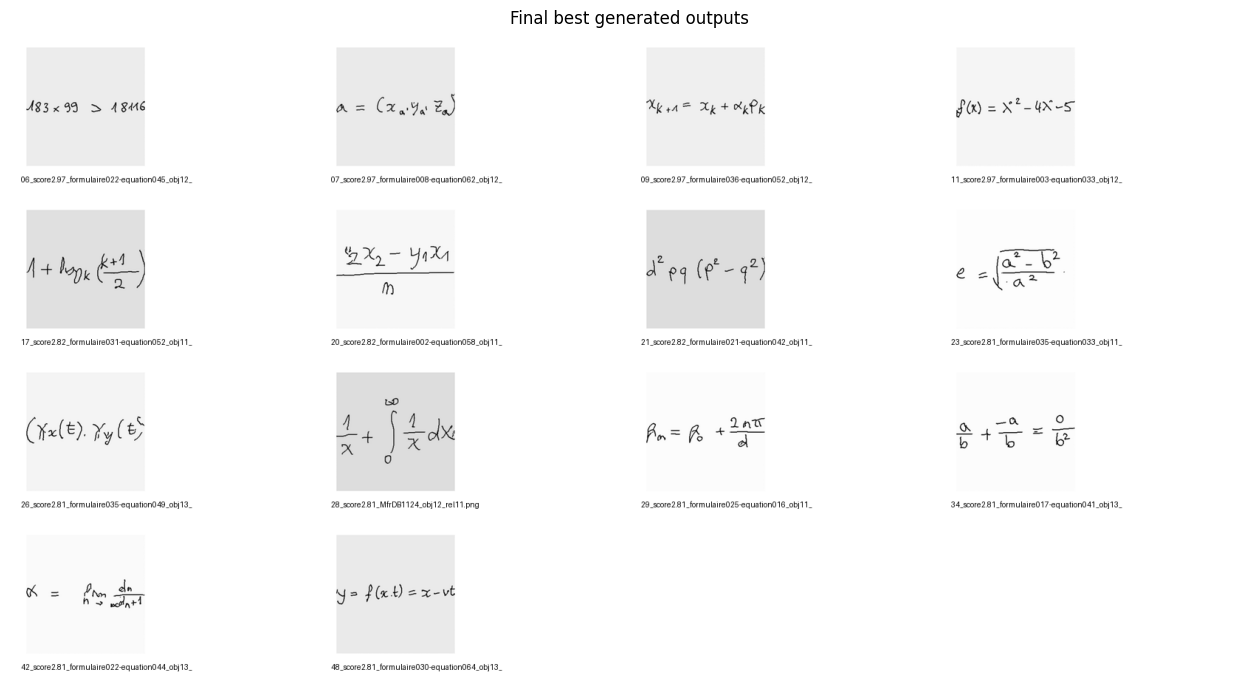

In [8]:
def make_contact_sheet(image_paths, out_path, cols=4, thumb_w=420, thumb_h=220):
    paths = sorted(image_paths)
    rows = (len(paths) + cols - 1) // cols
    sheet = Image.new('RGB', (cols * thumb_w, rows * thumb_h), 'white')
    draw = ImageDraw.Draw(sheet)
    for idx, path in enumerate(paths):
        img = Image.open(path).convert('RGB')
        img.thumbnail((thumb_w - 30, thumb_h - 45), Image.Resampling.LANCZOS)
        x = (idx % cols) * thumb_w + 15
        y = (idx // cols) * thumb_h + 15
        sheet.paste(img, (x, y))
        draw.text((x, y + img.height + 5), path.name[:45], fill=(0, 0, 0))
    sheet.save(out_path)
    return sheet

best_sheet = make_contact_sheet(best_dir.glob('*.png'), out_root / 'hmeg_final_best_contact_sheet.png')
showable_sheet = make_contact_sheet(showable_dir.glob('*.png'), out_root / 'hmeg_final_showable_contact_sheet.png')

plt.figure(figsize=(16, 10))
plt.imshow(best_sheet)
plt.axis('off')
plt.title('Final best generated outputs')
plt.show()


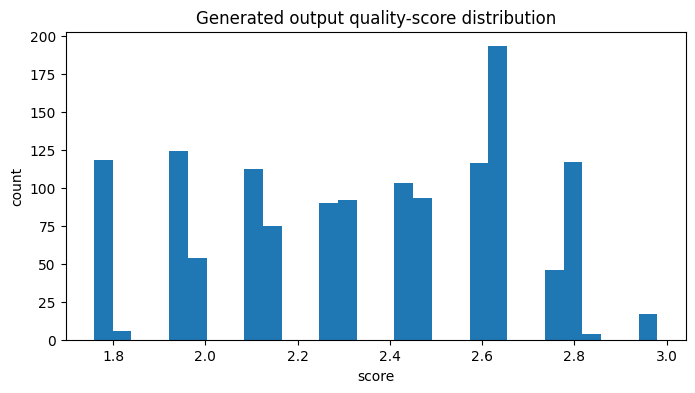

In [9]:
scores = [x[0] for x in records]
plt.figure(figsize=(8, 4))
plt.hist(scores, bins=30)
plt.title('Generated output quality-score distribution')
plt.xlabel('score')
plt.ylabel('count')
plt.show()


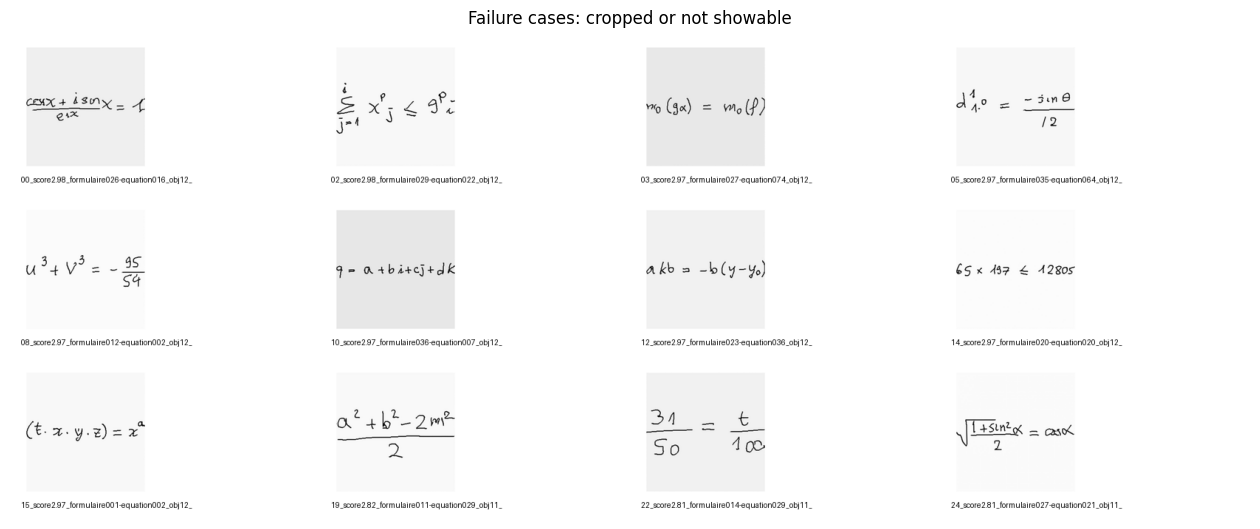

In [10]:
failure_paths = sorted(reject_dir.glob('*.png'))[:12]
if failure_paths:
    failure_sheet = make_contact_sheet(failure_paths, out_root / 'hmeg_failure_examples_contact_sheet.png', cols=4)
    plt.figure(figsize=(16, 8))
    plt.imshow(failure_sheet)
    plt.axis('off')
    plt.title('Failure cases: cropped or not showable')
    plt.show()


In [11]:
!zip -r /content/hmeg_project_outputs.zip /content/hmeg_project_outputs
from google.colab import files
files.download('/content/hmeg_project_outputs.zip')


  adding: content/hmeg_project_outputs/ (stored 0%)
  adding: content/hmeg_project_outputs/hmeg_failure_examples_contact_sheet.png (deflated 9%)
  adding: content/hmeg_project_outputs/hmeg_final_best_contact_sheet.png (deflated 11%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/ (stored 0%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/formulaire007-equation038_obj9_rel8.png (deflated 6%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/TrainData2_12_sub_41_obj12_rel11.png (deflated 2%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/KME2G3_5_sub_95_obj11_rel13.png (deflated 4%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/89_rosario_obj10_rel9.png (deflated 8%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/109_miguel_obj13_rel12.png (deflated 1%)
  adding: content/hmeg_project_outputs/hmeg_readable_candidates/formulaire026-equation016_obj12_rel11.png (deflated 5%)
  adding: content/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
!pip install -q opencv-python scikit-image scikit-learn torchvision torch pillow matplotlib pandas numpy tqdm


In [13]:
import os
import math
import random
import shutil
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps, ImageEnhance, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.morphology import skeletonize
from skimage.filters import threshold_otsu
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, classification_report
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights

random.seed(7)
np.random.seed(7)
torch.manual_seed(7)

project_root = Path('/content/handwriting_authenticity_style_project')
input_root = Path('/content/handwriting_samples')
style_root = project_root / 'style_dataset'
output_root = project_root / 'outputs'
for pth in [project_root, style_root, output_root]:
    pth.mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)


cuda


In [14]:
def list_images(folder):
    exts = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff', '.webp'}
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted([p for p in folder.rglob('*') if p.suffix.lower() in exts and p.is_file()])


def has_labelled_dataset(folder):
    folder = Path(folder)
    if not folder.exists():
        return False
    subdirs = [p for p in folder.iterdir() if p.is_dir()]
    counts = [len(list_images(p)) for p in subdirs]
    return len([c for c in counts if c >= 2]) >= 2


def load_labelled_dataset(folder, limit_per_writer=40):
    records = []
    for writer_dir in sorted([p for p in Path(folder).iterdir() if p.is_dir()]):
        imgs = list_images(writer_dir)[:limit_per_writer]
        if len(imgs) >= 2:
            for img in imgs:
                records.append({'path': str(img), 'writer': writer_dir.name, 'source': 'folder'})
    return pd.DataFrame(records)


def find_unlabelled_handwriting_images():
    candidates = []
    for d in [
        Path('/content/hmeg_project_outputs/final/hmeg_final_showable'),
        Path('/content/hmeg_project_outputs/final/hmeg_final_best'),
        Path('/content/hmeg_project_outputs/hmeg_readable_selected'),
        Path('/content/HMEG'),
        Path('/content')
    ]:
        candidates.extend(list_images(d))
    filtered = []
    for p in candidates:
        name = str(p).lower()
        if any(x in name for x in ['handwriting_authenticity_style_project', '.ipynb_checkpoints']):
            continue
        filtered.append(p)
    return sorted(set(filtered))[:120]


def synthetic_style_variant(img, writer_id, sample_id):
    img = img.convert('L')
    img = ImageOps.autocontrast(img)
    arr = np.array(img)
    if arr.mean() < 127:
        img = ImageOps.invert(img)
    inv = ImageOps.invert(img)
    bbox = inv.getbbox()
    if bbox:
        img = img.crop(bbox)
    rng = np.random.default_rng(writer_id * 1000 + sample_id)
    angle_base = [-11, -6, -2, 3, 8, 13, -14, 0][writer_id % 8]
    scale_x = [0.82, 0.9, 1.0, 1.12, 1.25, 1.38, 0.96, 1.08][writer_id % 8]
    scale_y = [0.88, 1.0, 1.1, 1.2, 0.95, 1.05, 1.16, 0.92][writer_id % 8]
    contrast = [0.75, 0.95, 1.1, 1.3, 1.5, 1.8, 1.2, 0.85][writer_id % 8]
    blur = [0, 1, 0, 1, 0, 0, 1, 0][writer_id % 8]
    thickness = [-1, 0, 1, 2, -1, 1, 2, 0][writer_id % 8]
    img = ImageEnhance.Contrast(img).enhance(float(contrast + rng.normal(0, 0.05)))
    w = max(80, int(img.width * scale_x * rng.uniform(0.94, 1.06)))
    h = max(40, int(img.height * scale_y * rng.uniform(0.94, 1.06)))
    img = img.resize((w, h), Image.Resampling.BICUBIC)
    img = img.rotate(float(angle_base + rng.normal(0, 2.0)), expand=True, fillcolor=255)
    arr = np.array(img)
    bin_img = (arr < 210).astype(np.uint8) * 255
    if thickness > 0:
        kernel = np.ones((1 + thickness, 1 + thickness), np.uint8)
        bin_img = cv2.dilate(bin_img, kernel, iterations=1)
    elif thickness < 0:
        kernel = np.ones((2, 2), np.uint8)
        bin_img = cv2.erode(bin_img, kernel, iterations=1)
    arr = 255 - bin_img
    if blur:
        arr = cv2.GaussianBlur(arr, (3, 3), 0)
    noise = rng.normal(0, 5, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    img = Image.fromarray(arr).convert('L')
    bg = Image.new('L', (max(360, img.width + 50), max(120, img.height + 50)), 255)
    bg.paste(img, (25, 25))
    return bg


def build_synthetic_dataset(base_images, writers=8, samples_per_writer=12):
    if style_root.exists():
        shutil.rmtree(style_root)
    style_root.mkdir(parents=True, exist_ok=True)
    if len(base_images) == 0:
        fallback = project_root / 'fallback_base.png'
        canvas = Image.new('L', (700, 180), 255)
        draw = ImageDraw.Draw(canvas)
        try:
            font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 52)
        except Exception:
            font = None
        draw.text((40, 55), 'x^2 + y^2 = z^2', fill=0, font=font)
        canvas.save(fallback)
        base_images = [fallback]
    records = []
    for wid in range(writers):
        wdir = style_root / f'writer_{wid:02d}'
        wdir.mkdir(parents=True, exist_ok=True)
        for sid in range(samples_per_writer):
            src = base_images[(wid * samples_per_writer + sid) % len(base_images)]
            img = Image.open(src).convert('L')
            out_img = synthetic_style_variant(img, wid, sid)
            out_path = wdir / f'writer_{wid:02d}_sample_{sid:02d}.png'
            out_img.save(out_path)
            records.append({'path': str(out_path), 'writer': f'writer_{wid:02d}', 'source': 'synthetic'})
    return pd.DataFrame(records)

if has_labelled_dataset(input_root):
    df = load_labelled_dataset(input_root)
else:
    base_images = find_unlabelled_handwriting_images()
    df = build_synthetic_dataset(base_images)

print(df.shape)
print(df['writer'].value_counts().head(20))
df.head()


(96, 3)
writer
writer_00    12
writer_01    12
writer_02    12
writer_03    12
writer_04    12
writer_05    12
writer_06    12
writer_07    12
Name: count, dtype: int64


,path,writer,source
0,/content/handwriting_authenticity_style_projec...,writer_00,synthetic
1,/content/handwriting_authenticity_style_projec...,writer_00,synthetic
2,/content/handwriting_authenticity_style_projec...,writer_00,synthetic
3,/content/handwriting_authenticity_style_projec...,writer_00,synthetic
4,/content/handwriting_authenticity_style_projec...,writer_00,synthetic


In [15]:
def read_gray(path):
    img = Image.open(path).convert('L')
    img = ImageOps.autocontrast(img)
    arr = np.array(img)
    if arr.mean() < 127:
        arr = 255 - arr
    return arr


def ink_mask(arr):
    try:
        t = threshold_otsu(arr)
    except Exception:
        t = 200
    return arr < min(t, 220)


def crop_to_ink(arr, pad=12):
    mask = ink_mask(arr)
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return arr
    y0, y1 = max(0, ys.min() - pad), min(arr.shape[0], ys.max() + pad + 1)
    x0, x1 = max(0, xs.min() - pad), min(arr.shape[1], xs.max() + pad + 1)
    return arr[y0:y1, x0:x1]


def resize_pad(arr, size=224):
    arr = crop_to_ink(arr)
    h, w = arr.shape[:2]
    scale = min((size - 20) / max(w, 1), (size - 20) / max(h, 1))
    nw, nh = max(1, int(w * scale)), max(1, int(h * scale))
    resized = cv2.resize(arr, (nw, nh), interpolation=cv2.INTER_AREA)
    canvas = np.ones((size, size), dtype=np.uint8) * 255
    y = (size - nh) // 2
    x = (size - nw) // 2
    canvas[y:y+nh, x:x+nw] = resized
    return canvas


def projection_entropy(v):
    v = np.asarray(v, dtype=np.float64)
    s = v.sum()
    if s <= 0:
        return 0.0
    p = v / s
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def orientation_stats(mask):
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    angles = []
    areas = []
    for cnt in contours:
        if len(cnt) < 8:
            continue
        pts = cnt.reshape(-1, 2).astype(np.float32)
        pts -= pts.mean(axis=0)
        cov = np.cov(pts.T)
        vals, vecs = np.linalg.eigh(cov)
        v = vecs[:, np.argmax(vals)]
        angle = math.degrees(math.atan2(v[1], v[0]))
        if angle > 90:
            angle -= 180
        if angle < -90:
            angle += 180
        angles.append(angle)
        areas.append(cv2.contourArea(cnt))
    if len(angles) == 0:
        return 0.0, 0.0, 0.0
    angles = np.array(angles)
    areas = np.array(areas) + 1e-6
    return float(np.average(angles, weights=areas)), float(np.std(angles)), float(np.median(angles))


def stroke_width_stats(mask):
    if mask.sum() < 10:
        return 0.0, 0.0, 0.0
    dist = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)
    skel = skeletonize(mask).astype(bool)
    vals = dist[skel] * 2.0
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 0.0, 0.0, 0.0
    return float(vals.mean()), float(vals.std()), float(np.percentile(vals, 90))


def handcrafted_features(path):
    arr = resize_pad(read_gray(path), 224)
    mask = ink_mask(arr)
    ink_pixels = arr[mask]
    density = float(mask.mean())
    darkness = float((255 - ink_pixels).mean() / 255.0) if len(ink_pixels) else 0.0
    contrast = float(arr.std() / 255.0)
    ys, xs = np.where(mask)
    aspect = 0.0
    center_x = 0.0
    center_y = 0.0
    if len(xs):
        aspect = float((xs.max() - xs.min() + 1) / max((ys.max() - ys.min() + 1), 1))
        center_x = float(xs.mean() / arr.shape[1])
        center_y = float(ys.mean() / arr.shape[0])
    hproj = mask.sum(axis=1)
    vproj = mask.sum(axis=0)
    h_entropy = projection_entropy(hproj)
    v_entropy = projection_entropy(vproj)
    rows = np.where(hproj > np.percentile(hproj, 70))[0]
    baseline_slope = 0.0
    baseline_std = 0.0
    if len(xs) > 10:
        cols = []
        lows = []
        for x in range(mask.shape[1]):
            yv = np.where(mask[:, x])[0]
            if len(yv) > 0:
                cols.append(x)
                lows.append(yv.max())
        if len(cols) > 10:
            coeff = np.polyfit(cols, lows, 1)
            baseline_slope = float(coeff[0])
            baseline_std = float(np.std(np.array(lows) - np.polyval(coeff, cols)))
    angle_mean, angle_std, angle_median = orientation_stats(mask)
    sw_mean, sw_std, sw_p90 = stroke_width_stats(mask)
    components, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8), 8)
    component_count = max(0, components - 1)
    areas = stats[1:, cv2.CC_STAT_AREA] if components > 1 else np.array([0])
    area_mean = float(np.mean(areas)) if len(areas) else 0.0
    area_std = float(np.std(areas)) if len(areas) else 0.0
    return np.array([density, darkness, contrast, aspect, center_x, center_y, h_entropy, v_entropy, baseline_slope, baseline_std, angle_mean, angle_std, angle_median, sw_mean, sw_std, sw_p90, component_count, area_mean, area_std], dtype=np.float32)

feature_names = ['density','darkness','contrast','aspect','center_x','center_y','h_entropy','v_entropy','baseline_slope','baseline_std','angle_mean','angle_std','angle_median','stroke_width_mean','stroke_width_std','stroke_width_p90','component_count','component_area_mean','component_area_std']
X_hand = np.vstack([handcrafted_features(p) for p in tqdm(df['path'])])
hand_df = pd.DataFrame(X_hand, columns=feature_names)
hand_df.insert(0, 'writer', df['writer'].values)
hand_df.head()


  0%|          | 0/96 [00:00<?, ?it/s]

,writer,density,darkness,contrast,aspect,center_x,center_y,h_entropy,v_entropy,baseline_slope,baseline_std,angle_mean,angle_std,angle_median,stroke_width_mean,stroke_width_std,stroke_width_p90,component_count,component_area_mean,component_area_std
0,writer_00,0.041893,0.877280,0.183740,2.021277,0.662989,0.461973,6.132110,6.788321,0.209812,21.301477,15.007130,29.041466,-20.737986,3.259923,2.384148,6.3938,65.0,32.338463,70.830956
1,writer_00,0.024514,0.716847,0.123302,2.333333,0.492861,0.505121,5.943997,7.169783,0.228634,12.874262,-6.009285,26.383659,8.444067,2.359991,0.908758,4.0000,124.0,9.919354,30.548111
2,writer_00,0.033024,0.524910,0.108266,2.043011,0.531945,0.518269,6.213150,7.270609,0.259318,9.893748,-15.437513,45.369259,-40.306591,2.167032,0.631476,2.0000,226.0,7.331859,20.737947
3,writer_00,0.010941,0.675403,0.075215,2.695652,0.490746,0.498959,5.777807,6.603216,0.216222,7.972882,-6.478081,57.234703,11.740669,2.066032,0.280965,2.0000,40.0,13.725000,11.146720
4,writer_00,0.009347,0.662126,0.068062,3.795918,0.465457,0.494917,5.250319,6.638752,0.149791,6.799925,6.699828,58.814922,21.783953,2.045714,0.185692,2.0000,43.0,10.906977,8.618029


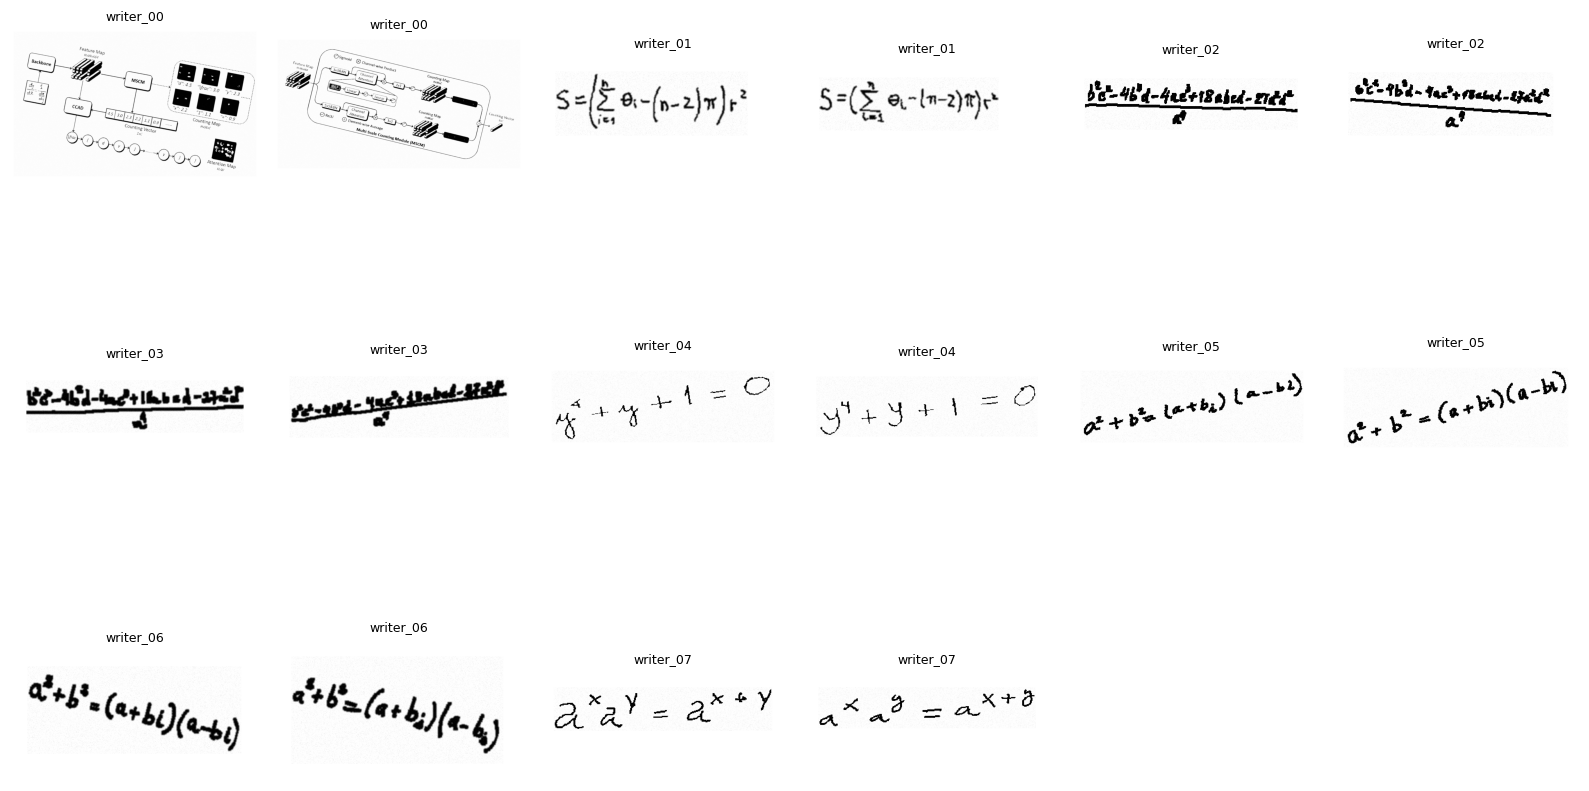

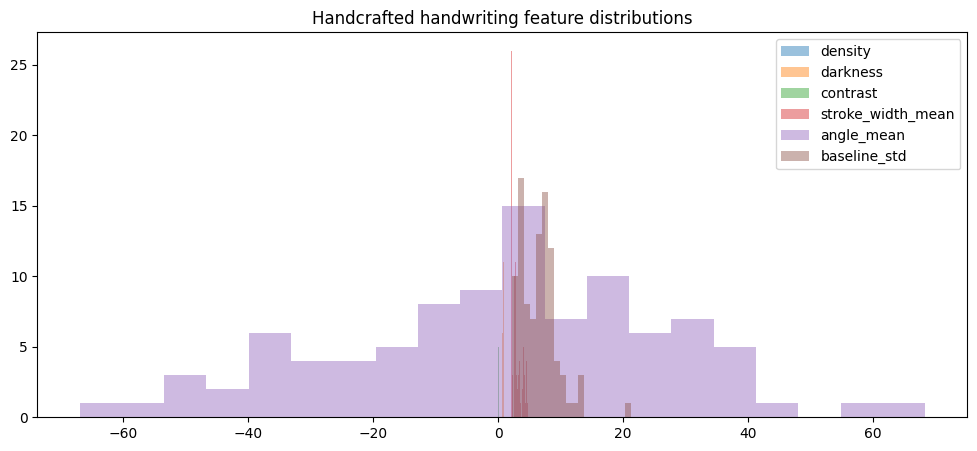

In [16]:
def show_image_grid(paths, titles=None, cols=6, figsize=(16, 8)):
    paths = list(paths)
    rows = int(math.ceil(len(paths) / cols))
    plt.figure(figsize=figsize)
    for i, pth in enumerate(paths):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(read_gray(pth), cmap='gray')
        plt.axis('off')
        if titles is not None:
            plt.title(str(titles[i]), fontsize=9)
    plt.tight_layout()
    plt.show()

sample_paths = []
sample_titles = []
for writer, part in df.groupby('writer'):
    sample_paths.extend(part['path'].head(2).tolist())
    sample_titles.extend([writer] * min(2, len(part)))
show_image_grid(sample_paths[:24], sample_titles[:24], cols=6, figsize=(16, 10))

plt.figure(figsize=(12, 5))
for col in ['density', 'darkness', 'contrast', 'stroke_width_mean', 'angle_mean', 'baseline_std']:
    plt.hist(hand_df[col], bins=20, alpha=0.45, label=col)
plt.legend()
plt.title('Handcrafted handwriting feature distributions')
plt.show()


In [17]:
class HandwritingImageDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)
        self.transform = T.Compose([
            T.ToPILImage(),
            T.Grayscale(num_output_channels=3),
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        arr = resize_pad(read_gray(self.paths[idx]), 224)
        return self.transform(arr)

weights = ResNet18_Weights.DEFAULT
cnn = resnet18(weights=weights)
cnn.fc = nn.Identity()
cnn = cnn.to(device).eval()
loader = DataLoader(HandwritingImageDataset(df['path']), batch_size=32, shuffle=False, num_workers=2)
cnn_features = []
with torch.no_grad():
    for batch in tqdm(loader):
        batch = batch.to(device)
        emb = cnn(batch).detach().cpu().numpy()
        cnn_features.append(emb)
X_cnn = np.vstack(cnn_features).astype(np.float32)
print(X_cnn.shape)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 97.2MB/s]


  0%|          | 0/3 [00:00<?, ?it/s]

(96, 512)


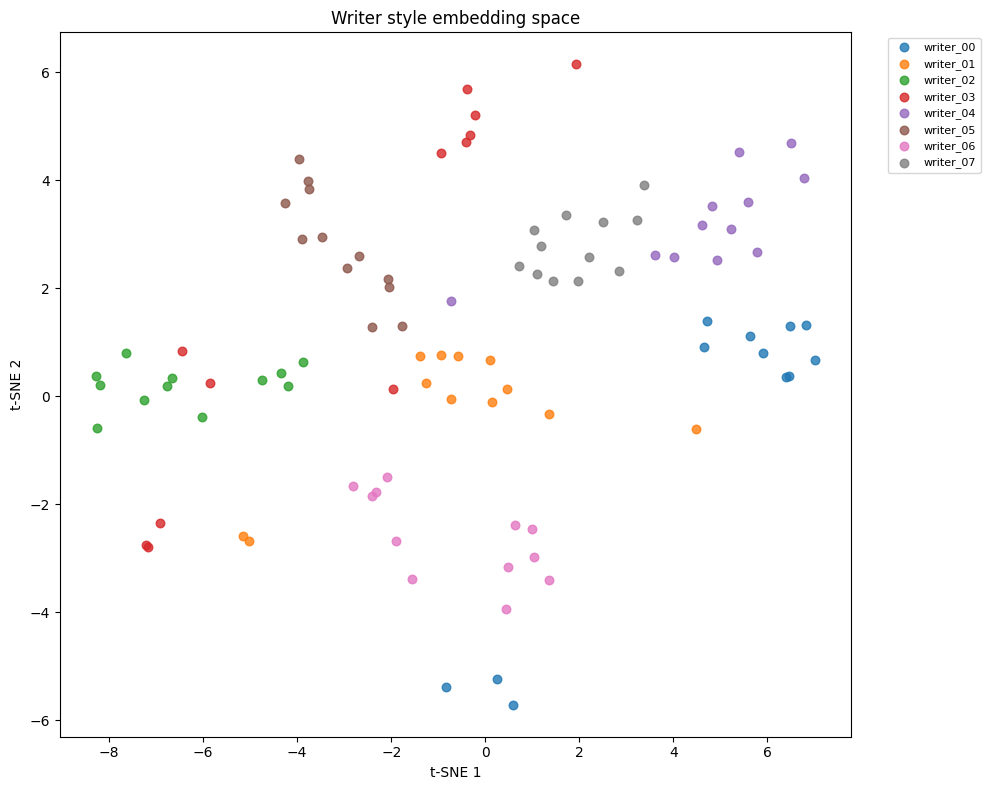

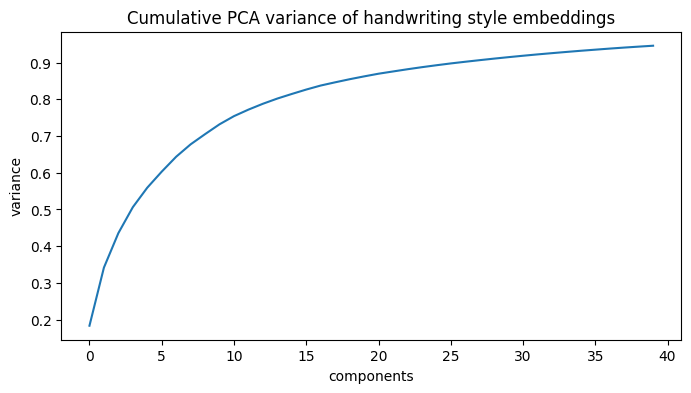

In [18]:
scaler_hand = StandardScaler()
scaler_cnn = StandardScaler()
X_hand_scaled = scaler_hand.fit_transform(X_hand)
X_cnn_scaled = scaler_cnn.fit_transform(X_cnn)
X = np.hstack([X_cnn_scaled, X_hand_scaled]).astype(np.float32)
labels = df['writer'].values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

pca = PCA(n_components=min(40, X.shape[0] - 1, X.shape[1]), random_state=7)
X_pca = pca.fit_transform(X)

perplexity = max(5, min(30, (len(df) - 1) // 3))
tsne = TSNE(n_components=2, perplexity=perplexity, learning_rate='auto', init='pca', random_state=7)
X_2d = tsne.fit_transform(X_pca)

plot_df = pd.DataFrame({'x': X_2d[:, 0], 'y': X_2d[:, 1], 'writer': labels})
plt.figure(figsize=(10, 8))
for writer, part in plot_df.groupby('writer'):
    plt.scatter(part['x'], part['y'], label=writer, s=38, alpha=0.8)
plt.title('Writer style embedding space')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.title('Cumulative PCA variance of handwriting style embeddings')
plt.xlabel('components')
plt.ylabel('variance')
plt.show()


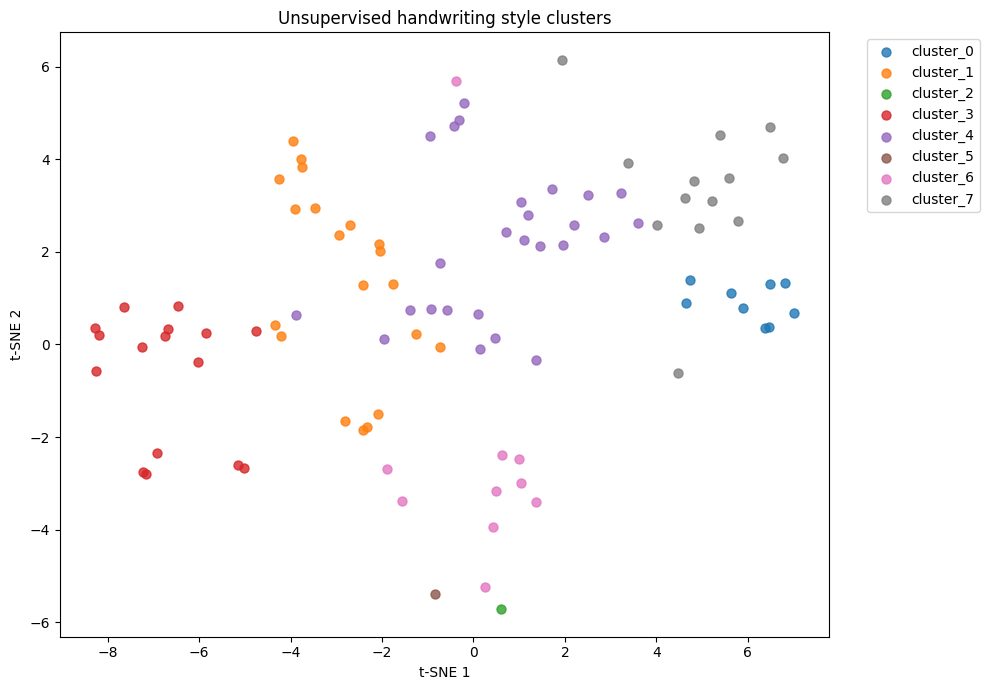

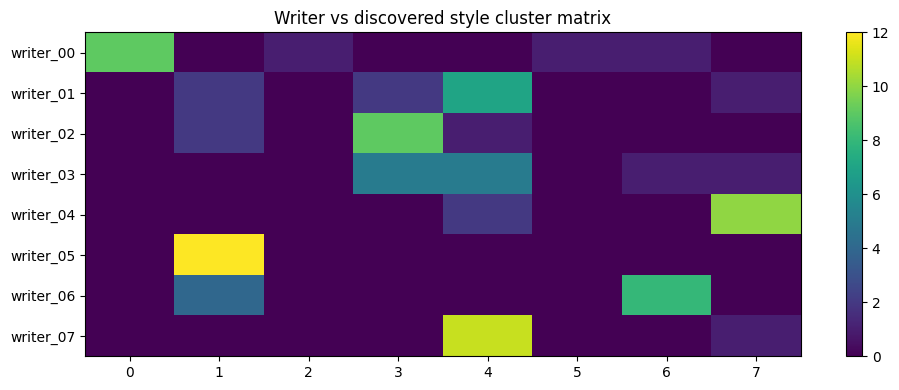

cluster,0,1,2,3,4,5,6,7
writer,,,,,,,,
writer_00,9,0,1,0,0,1,1,0
writer_01,0,2,0,2,7,0,0,1
writer_02,0,2,0,9,1,0,0,0
writer_03,0,0,0,5,5,0,1,1
writer_04,0,0,0,0,2,0,0,10
writer_05,0,12,0,0,0,0,0,0
writer_06,0,4,0,0,0,0,8,0
writer_07,0,0,0,0,11,0,0,1


In [19]:
k = min(len(np.unique(y)), 8)
kmeans = KMeans(n_clusters=k, random_state=7, n_init='auto')
clusters = kmeans.fit_predict(X_pca)
plot_df['cluster'] = clusters
plt.figure(figsize=(10, 7))
for cluster, part in plot_df.groupby('cluster'):
    plt.scatter(part['x'], part['y'], label=f'cluster_{cluster}', s=42, alpha=0.8)
plt.title('Unsupervised handwriting style clusters')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
plt.tight_layout()
plt.show()

ct = pd.crosstab(pd.Series(labels, name='writer'), pd.Series(clusters, name='cluster'))
plt.figure(figsize=(10, max(4, 0.45 * ct.shape[0])))
plt.imshow(ct.values, aspect='auto')
plt.xticks(range(ct.shape[1]), ct.columns)
plt.yticks(range(ct.shape[0]), ct.index)
plt.title('Writer vs discovered style cluster matrix')
plt.colorbar()
plt.tight_layout()
plt.show()
ct


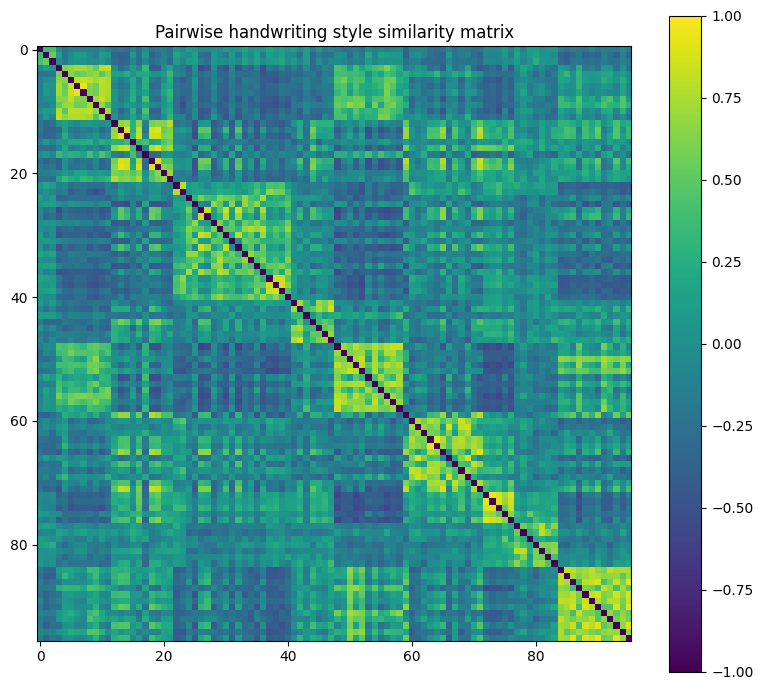

query 0 writer_00


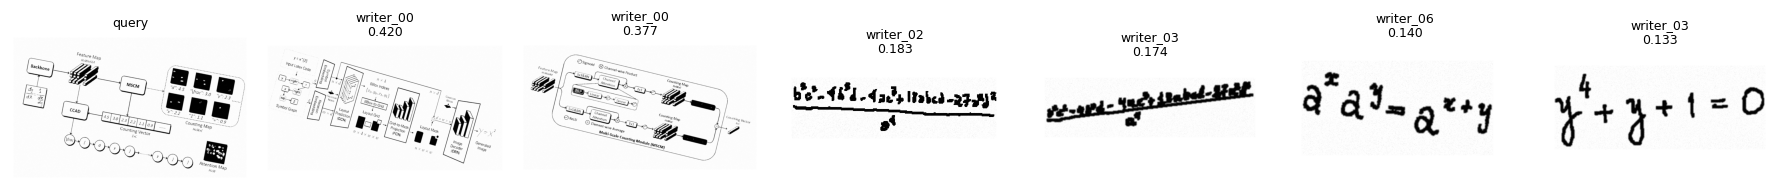

query 12 writer_01


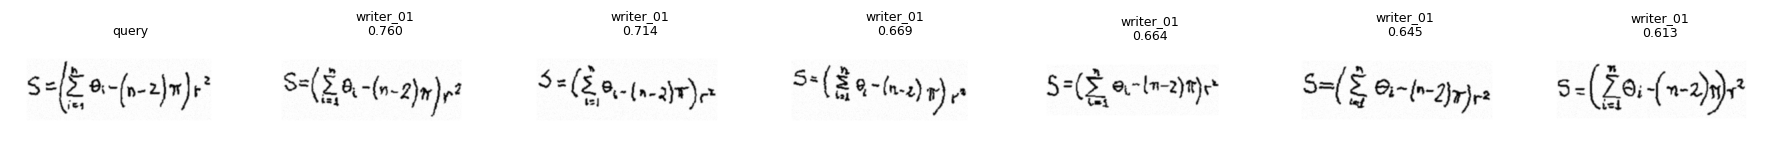

query 24 writer_02


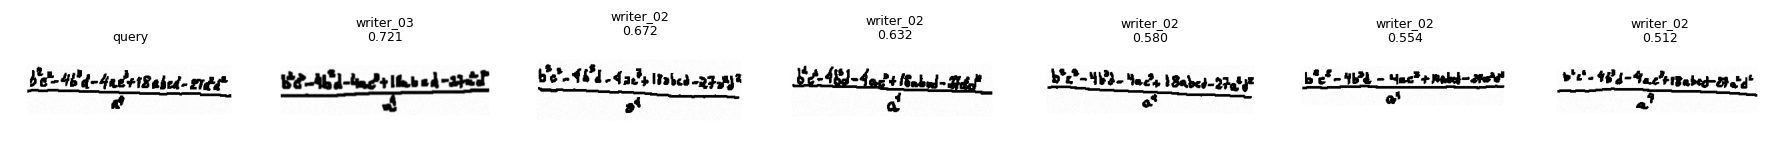

query 36 writer_03


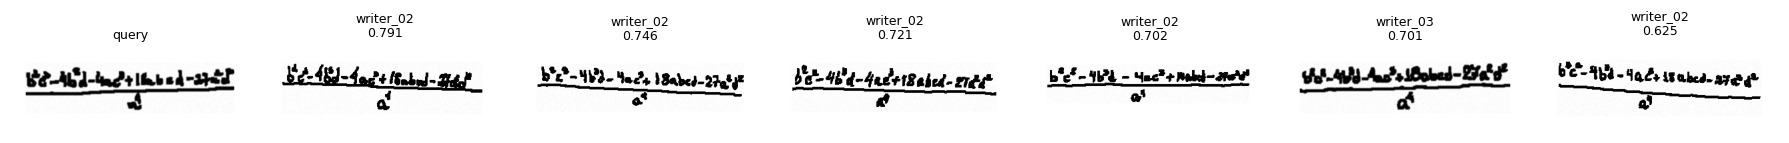

query 48 writer_04


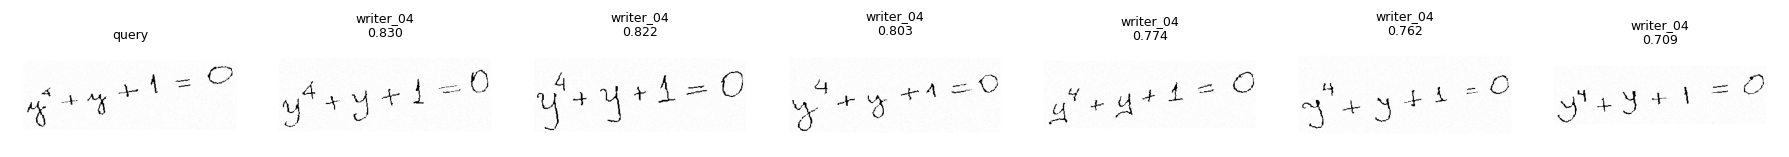

,rank,path,writer,similarity
0,1,/content/handwriting_authenticity_style_projec...,writer_00,0.419663
1,2,/content/handwriting_authenticity_style_projec...,writer_00,0.376590
2,3,/content/handwriting_authenticity_style_projec...,writer_02,0.182935
3,4,/content/handwriting_authenticity_style_projec...,writer_03,0.173767
4,5,/content/handwriting_authenticity_style_projec...,writer_06,0.140173
5,6,/content/handwriting_authenticity_style_projec...,writer_03,0.132730


In [20]:
S = cosine_similarity(X_pca)
np.fill_diagonal(S, -1)

plt.figure(figsize=(8, 7))
order = np.argsort(y)
plt.imshow(S[order][:, order], vmin=-1, vmax=1)
plt.title('Pairwise handwriting style similarity matrix')
plt.colorbar()
plt.tight_layout()
plt.show()


def retrieve_similar(query_index, top_k=6):
    sims = cosine_similarity(X_pca[query_index:query_index+1], X_pca)[0]
    sims[query_index] = -1
    idxs = np.argsort(-sims)[:top_k]
    paths = [df.iloc[query_index]['path']] + df.iloc[idxs]['path'].tolist()
    titles = ['query'] + [f"{df.iloc[i]['writer']}\n{float(sims[i]):.3f}" for i in idxs]
    show_image_grid(paths, titles, cols=top_k+1, figsize=(18, 4))
    return pd.DataFrame({'rank': range(1, top_k+1), 'path': df.iloc[idxs]['path'].values, 'writer': df.iloc[idxs]['writer'].values, 'similarity': sims[idxs]})

query_indices = []
for writer, part in df.groupby('writer'):
    query_indices.append(part.index[0])
query_indices = query_indices[:min(5, len(query_indices))]
retrieval_tables = []
for qi in query_indices:
    print('query', qi, df.iloc[qi]['writer'])
    retrieval_tables.append(retrieve_similar(qi, 6))
retrieval_tables[0]


                  precision    recall  f1-score   support

different_writer       0.81      0.81      0.81       158
     same_writer       0.81      0.81      0.81       159

        accuracy                           0.81       317
       macro avg       0.81      0.81      0.81       317
    weighted avg       0.81      0.81      0.81       317



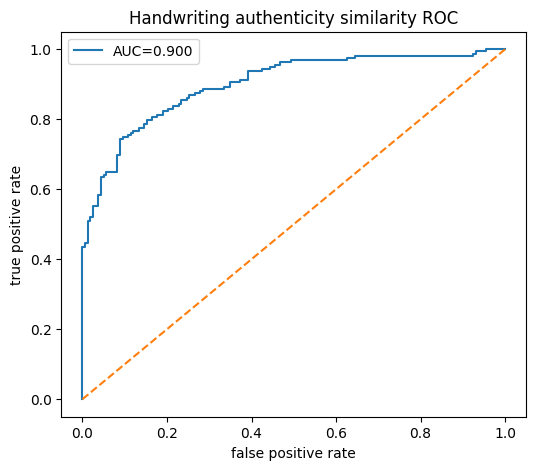

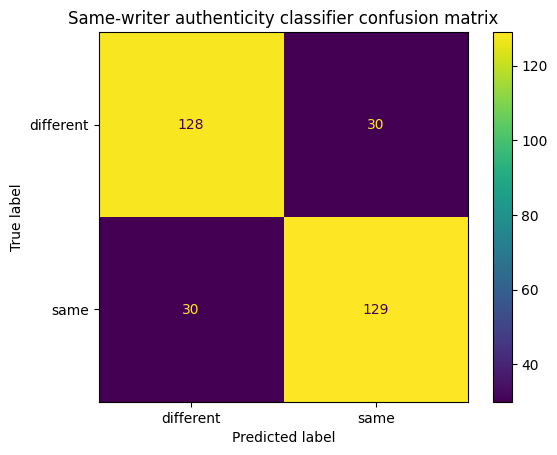

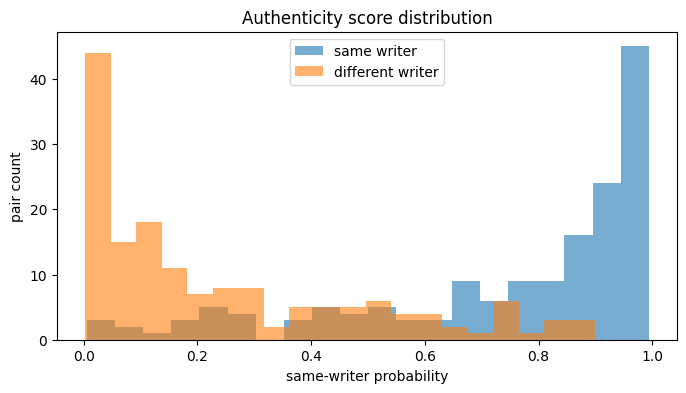

In [21]:
def make_pairs(labels, max_same_per_writer=80, max_diff=800):
    same = []
    diff = []
    label_to_indices = {}
    for i, lab in enumerate(labels):
        label_to_indices.setdefault(lab, []).append(i)
    for lab, idxs in label_to_indices.items():
        pairs = list(itertools.combinations(idxs, 2))
        random.shuffle(pairs)
        same.extend(pairs[:max_same_per_writer])
    all_indices = list(range(len(labels)))
    tries = 0
    while len(diff) < min(max_diff, len(same) * 2) and tries < max_diff * 20:
        a, b = random.sample(all_indices, 2)
        if labels[a] != labels[b]:
            diff.append((a, b))
        tries += 1
    n = min(len(same), len(diff))
    same = same[:n]
    diff = diff[:n]
    pairs = same + diff
    targets = np.array([1] * len(same) + [0] * len(diff))
    return pairs, targets


def pair_features(pairs):
    feats = []
    for a, b in pairs:
        va = X_pca[a]
        vb = X_pca[b]
        cos = cosine_similarity(va.reshape(1, -1), vb.reshape(1, -1))[0, 0]
        l1 = np.abs(va - vb)
        l2 = np.sqrt((va - vb) ** 2)
        stat = np.array([cos, np.linalg.norm(va - vb), np.mean(l1), np.max(l1)], dtype=np.float32)
        feats.append(np.hstack([stat, l1, l2]))
    return np.vstack(feats).astype(np.float32)

pairs, targets = make_pairs(labels)
X_pairs = pair_features(pairs)
X_train, X_test, y_train, y_test, pairs_train, pairs_test = train_test_split(X_pairs, targets, pairs, test_size=0.3, random_state=7, stratify=targets)
clf = LogisticRegression(max_iter=2000, class_weight='balanced')
clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=['different_writer', 'same_writer']))

fpr, tpr, thresholds = roc_curve(y_test, proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC={roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('Handwriting authenticity similarity ROC')
plt.legend()
plt.show()

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['different', 'same']).plot(values_format='d')
plt.title('Same-writer authenticity classifier confusion matrix')
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(proba[y_test == 1], bins=20, alpha=0.6, label='same writer')
plt.hist(proba[y_test == 0], bins=20, alpha=0.6, label='different writer')
plt.xlabel('same-writer probability')
plt.ylabel('pair count')
plt.title('Authenticity score distribution')
plt.legend()
plt.show()


same_writer_example writer_06 writer_06 probability 0.5322 cosine 0.3779


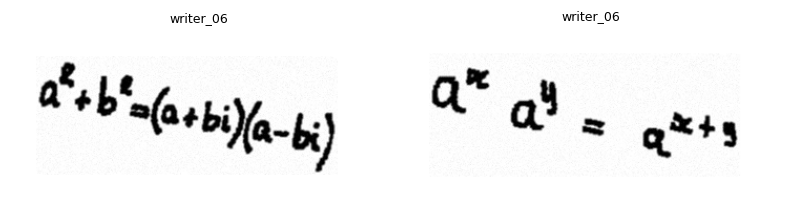

different_writer_example writer_03 writer_02 probability 0.0403 cosine 0.1935


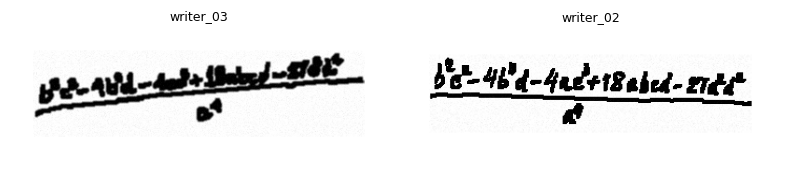

In [22]:
def authenticity_score(index_a, index_b):
    pf = pair_features([(index_a, index_b)])
    probability = float(clf.predict_proba(pf)[0, 1])
    cos = float(cosine_similarity(X_pca[index_a:index_a+1], X_pca[index_b:index_b+1])[0, 0])
    return probability, cos

same_pair = None
diff_pair = None
for a, b in pairs_test:
    if labels[a] == labels[b] and same_pair is None:
        same_pair = (a, b)
    if labels[a] != labels[b] and diff_pair is None:
        diff_pair = (a, b)
    if same_pair is not None and diff_pair is not None:
        break

for pair_name, pair in [('same_writer_example', same_pair), ('different_writer_example', diff_pair)]:
    a, b = pair
    prob, cos = authenticity_score(a, b)
    print(pair_name, labels[a], labels[b], 'probability', round(prob, 4), 'cosine', round(cos, 4))
    show_image_grid([df.iloc[a]['path'], df.iloc[b]['path']], [f'{labels[a]}', f'{labels[b]}'], cols=2, figsize=(8, 4))


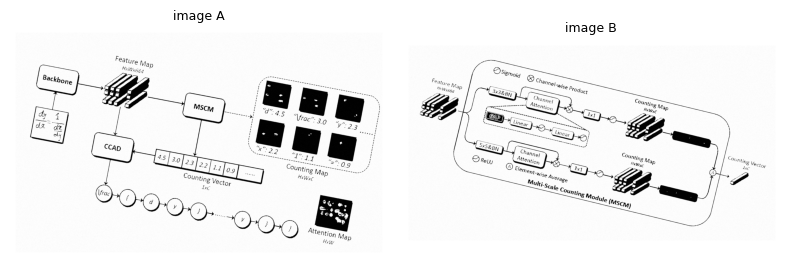

same_writer_probability 0.1846
style_cosine_similarity 0.3766


{'same_writer_probability': 0.1846032503587843,
 'style_cosine_similarity': 0.3765909969806671}

In [23]:
def compare_two_image_paths(path_a, path_b):
    temp = pd.DataFrame({'path': [str(path_a), str(path_b)], 'writer': ['unknown_a', 'unknown_b']})
    hand = np.vstack([handcrafted_features(path_a), handcrafted_features(path_b)])
    dataset = HandwritingImageDataset([path_a, path_b])
    loader = DataLoader(dataset, batch_size=2, shuffle=False)
    with torch.no_grad():
        batch = next(iter(loader)).to(device)
        cnn_emb = cnn(batch).detach().cpu().numpy().astype(np.float32)
    hand_scaled = scaler_hand.transform(hand)
    cnn_scaled = scaler_cnn.transform(cnn_emb)
    merged = np.hstack([cnn_scaled, hand_scaled]).astype(np.float32)
    emb = pca.transform(merged)
    cos = float(cosine_similarity(emb[0:1], emb[1:2])[0, 0])
    l1 = np.abs(emb[0] - emb[1])
    l2 = np.sqrt((emb[0] - emb[1]) ** 2)
    pf = np.hstack([[cos, np.linalg.norm(emb[0] - emb[1]), np.mean(l1), np.max(l1)], l1, l2]).reshape(1, -1).astype(np.float32)
    probability = float(clf.predict_proba(pf)[0, 1])
    show_image_grid([path_a, path_b], [f'image A', f'image B'], cols=2, figsize=(8, 4))
    print('same_writer_probability', round(probability, 4))
    print('style_cosine_similarity', round(cos, 4))
    return {'same_writer_probability': probability, 'style_cosine_similarity': cos}

example_a = df.iloc[0]['path']
example_b = df.iloc[1]['path']
compare_two_image_paths(example_a, example_b)


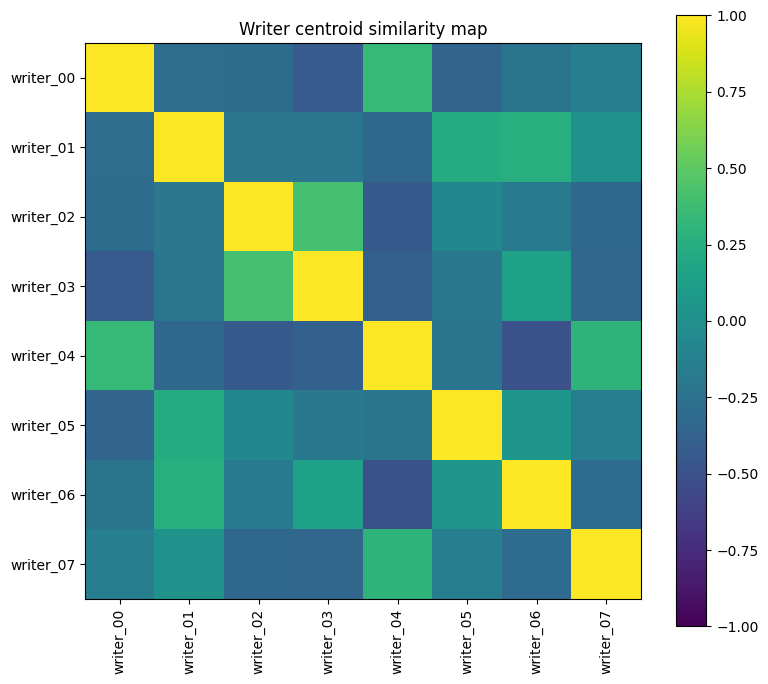

,writer,nearest_writer,centroid_similarity
3,writer_03,writer_02,0.404971
2,writer_02,writer_03,0.404971
0,writer_00,writer_04,0.337085
4,writer_04,writer_00,0.337085
7,writer_07,writer_04,0.302012
1,writer_01,writer_06,0.253487
6,writer_06,writer_01,0.253487
5,writer_05,writer_01,0.237779


In [24]:
writer_centroids = []
writer_names = []
for writer, part in df.groupby('writer'):
    idx = part.index.values
    writer_centroids.append(X_pca[idx].mean(axis=0))
    writer_names.append(writer)
writer_centroids = np.vstack(writer_centroids)
centroid_similarity = cosine_similarity(writer_centroids)

plt.figure(figsize=(8, 7))
plt.imshow(centroid_similarity, vmin=-1, vmax=1)
plt.xticks(range(len(writer_names)), writer_names, rotation=90)
plt.yticks(range(len(writer_names)), writer_names)
plt.title('Writer centroid similarity map')
plt.colorbar()
plt.tight_layout()
plt.show()

nearest_writers = []
for i, writer in enumerate(writer_names):
    sims = centroid_similarity[i].copy()
    sims[i] = -1
    j = int(np.argmax(sims))
    nearest_writers.append({'writer': writer, 'nearest_writer': writer_names[j], 'centroid_similarity': float(sims[j])})
pd.DataFrame(nearest_writers).sort_values('centroid_similarity', ascending=False)


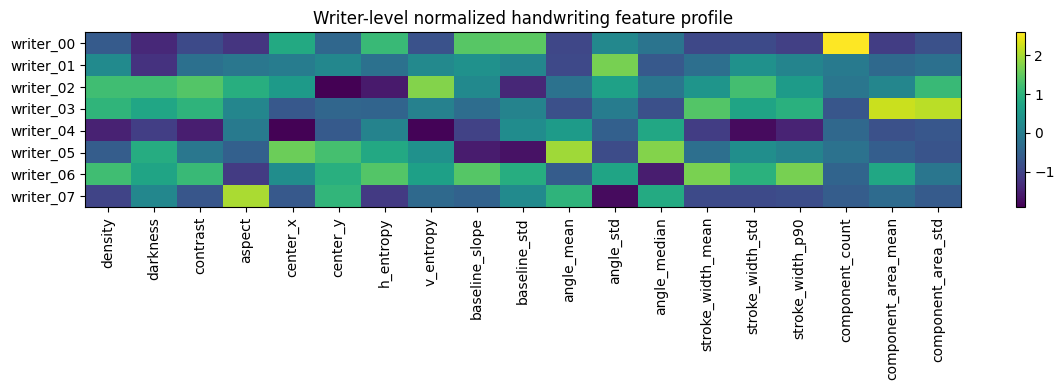

/content/handwriting_authenticity_style_project/outputs


In [25]:
feature_summary = hand_df.groupby('writer')[feature_names].mean()
plt.figure(figsize=(12, max(4, 0.45 * len(feature_summary))))
plt.imshow(StandardScaler().fit_transform(feature_summary), aspect='auto')
plt.xticks(range(len(feature_names)), feature_names, rotation=90)
plt.yticks(range(len(feature_summary.index)), feature_summary.index)
plt.title('Writer-level normalized handwriting feature profile')
plt.colorbar()
plt.tight_layout()
plt.show()

style_report = df.copy()
style_report['cluster'] = clusters
style_report['tsne_x'] = X_2d[:, 0]
style_report['tsne_y'] = X_2d[:, 1]
for col in feature_names:
    style_report[col] = hand_df[col].values
style_report.to_csv(output_root / 'style_embedding_records.csv', index=False)
np.save(output_root / 'style_embeddings_pca.npy', X_pca)
np.save(output_root / 'style_embeddings_tsne.npy', X_2d)
feature_summary.to_csv(output_root / 'writer_feature_summary.csv')
print(output_root)


In [26]:
!zip -r /content/handwriting_authenticity_style_project_outputs.zip /content/handwriting_authenticity_style_project
try:
    from google.colab import files
    files.download('/content/handwriting_authenticity_style_project_outputs.zip')
except Exception as e:
    print('/content/handwriting_authenticity_style_project_outputs.zip')


  adding: content/handwriting_authenticity_style_project/ (stored 0%)
  adding: content/handwriting_authenticity_style_project/style_dataset/ (stored 0%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/ (stored 0%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_08.png (deflated 1%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_09.png (deflated 1%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_01.png (deflated 1%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_05.png (deflated 1%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_02.png (deflated 1%)
  adding: content/handwriting_authenticity_style_project/style_dataset/writer_01/writer_01_sample_07.png (deflated 1%)
  adding: content/handwriting_authenti

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>